# A branching process: will it die out, or break out?

*Beyond the scriptum — an application.*

---

One infected person infects a random number of others, each of them again, and so on. One customer
recommends a service to a random number of acquaintances. One neutron triggers a random number of
further fissions. It is all the same model: a **branching process**.

The question is the same every time and has a surprisingly sharp answer:

> Will it die out, or will it grow without bound?

The answer depends on a single number — the mean number of offspring $R_0$ — and it is
**discontinuous**. For $R_0 \le 1$ the process dies out with certainty, for $R_0 > 1$ there is a
positive chance of survival. No smooth transition, a break at a single point.

This notebook brings two new things into the repository:

1. **Feedback**: until now the events were independent. Here every event breeds further ones.
2. **A phase transition**: the behaviour changes qualitatively at a single point.

And it has an exact check: the probability of extinction is **the smallest root of the equation
$s = G(s)$**, where $G$ is the generating function of the number of offspring — the same $G$ we used
for the clusters of claims in `applications/insurance_realistic`.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def poisson(lam):
    '''The number of offspring. For small λ a product of uniform numbers (exercise 3), for large ones the normal
    approximation — it is here only for speed, for large populations accuracy does not matter.'''
    if lam > 60:
        return max(0, int(round(random.gauss(lam, math.sqrt(lam)))))
    L, p, k = math.exp(-lam), 1.0, 0
    while True:
        p *= random.random()
        if p < L:
            return k
        k += 1

## 1. The model and the exact solution

We start with one infected individual. Each individual independently infects $X$ others, where $X$
has a distribution with generating function

$$G(s) = E\,s^X = \sum_k P(X = k)\,s^k, \qquad R_0 = E X = G'(1).$$

For the Poisson distribution $G(s) = e^{R_0(s-1)}$.

### Why the probability of extinction is a root of $s = G(s)$

Let $q$ be the probability that the whole process dies out. The first individual has $X$ offspring and
**each of his $X$ branches is an independent copy of the same process**. For the whole to die out,
all of them must die out:

$$q = \sum_k P(X=k)\,q^k = G(q).$$

So $q$ is a fixed point of $G$. One is always one (dying out "completely" is formally possible), but a
theorem holds: **the probability we are after is the smallest non-negative root**. And that is less
than 1 exactly when $R_0 > 1$.

We find the root by plain iteration $s_{k+1} = G(s_k)$ starting from zero — it converges from below to
the smallest root.

In [2]:
def G_poisson(s, R0):
    return math.exp(R0 * (s - 1))


def extinction_exact(R0, iterations=2000):
    '''The smallest non-negative root of the equation s = G(s), by iteration from zero.

    For R0 <= 1 the root equals 1 (extinction is certain). We return it directly, because
    exactly at the critical point the iteration would converge so slowly that even after two
    thousand steps it would give 0.999 — and in the table that would look like an uncertainty
    that is not there.
    '''
    if R0 <= 1.0:
        return 1.0
    s = 0.0
    for _ in range(iterations):
        s = G_poisson(s, R0)
    return s


def simulate_branching(R0, maxgen=300, threshold=2000):
    '''One run. Returns (died out, number of generations, maximum population size).

    If the population exceeds the threshold, we consider the process survived — the chance of dying
    out from so large a population is astronomically small (it is q^n for n individuals).
    '''
    n, largest = 1, 1
    for g in range(maxgen):
        if n == 0:
            return True, g, largest
        if n > threshold:
            return False, g, largest
        n = poisson(n * R0)        # the sum of n independent Poissons is Poisson(n·R0)
        largest = max(largest, n)
    return n == 0, maxgen, largest


M_ = 20_000
print(f"{'R0':>5s} {'simulation':>11s} {'exact':>9s} {'difference':>11s}")
R0_values = (0.8, 1.0, 1.2, 1.5, 2.0, 3.0)
sim_q, exact_q = [], []
for R0 in R0_values:
    died = sum(simulate_branching(R0)[0] for _ in range(M_)) / M_
    exact = extinction_exact(R0)
    sim_q.append(died); exact_q.append(exact)
    print(f"{R0:>5.1f} {died:>11.4f} {exact:>9.4f} {died - exact:>+11.4f}")

print("\nIt matches everywhere except at R0 = 1. There extinction is certain (q = 1), but it takes so long")
print("that the population threshold cuts it off — see section 3.")

   R0  simulation     exact  difference
  0.8      1.0000    1.0000     +0.0000
  1.0      0.9935    1.0000     -0.0065


  1.2      0.6889    0.6863     +0.0026
  1.5      0.4063    0.4172     -0.0108


  2.0      0.2049    0.2032     +0.0017
  3.0      0.0618    0.0595     +0.0023

It matches everywhere except at R0 = 1. There extinction is certain (q = 1), but it takes so long
that the population threshold cuts it off — see section 3.


## 2. The phase transition

What is interesting is **how** the probability of extinction changes with $R_0$. It is not a smooth
transition — up to $R_0 = 1$ it equals one, then it starts to fall, and at that point it has a kink.

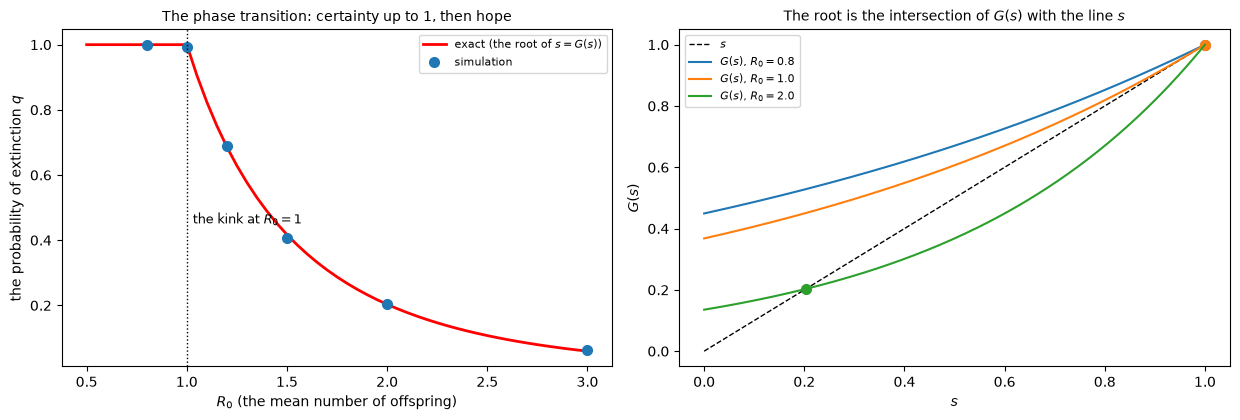

In [3]:
R0_fine = [0.5 + 0.05 * i for i in range(51)]
q_exact = [extinction_exact(R0) for R0 in R0_fine]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.plot(R0_fine, q_exact, "r-", lw=2, label="exact (the root of $s = G(s)$)")
ax.plot(R0_values, sim_q, "o", ms=7, color="tab:blue", label="simulation")
ax.axvline(1.0, color="k", ls=":", lw=1)
ax.text(1.03, 0.45, "the kink at $R_0 = 1$", fontsize=9)
ax.set_xlabel("$R_0$ (the mean number of offspring)")
ax.set_ylabel("the probability of extinction $q$")
ax.set_title("The phase transition: certainty up to 1, then hope", fontsize=10)
ax.legend(fontsize=8)

# the graphical solution of s = G(s)
ax = axes[1]
ss = [i / 200 for i in range(201)]
ax.plot(ss, ss, "k--", lw=1, label="$s$")
for R0, color in ((0.8, "tab:blue"), (1.0, "tab:orange"), (2.0, "tab:green")):
    ax.plot(ss, [G_poisson(s, R0) for s in ss], color=color, label=f"$G(s)$, $R_0 = {R0}$")
    q = extinction_exact(R0)
    ax.plot([q], [q], "o", color=color, ms=7)
ax.set_xlabel("$s$")
ax.set_ylabel("$G(s)$")
ax.set_title("The root is the intersection of $G(s)$ with the line $s$", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The right-hand picture shows why the kink is exactly at one. $G$ is convex and $G(1) = 1$, so the
line $s$ crosses it below one **exactly when** $G$ is steeper than the line at the point 1, i.e. when
$G'(1) = R_0 > 1$. The whole extinction theorem fits into a single picture.

## 3. The critical case $R_0 = 1$

The boundary is special. At $R_0 = 1$ extinction is **certain** — but the population does not change
on average and the survival time is disproportionately long. The mean time to extinction is in fact
**infinite**, even though extinction occurs with probability 1.

That is precisely why the table above gave us $0.99$ instead of $1.00$: some runs we cut off at the
population threshold.

In [4]:
print(f"{'R0':>6s} {'fraction died out':>18s} {'exact q':>9s} {'median generations*':>21s} {'longest run*':>13s}")
for R0 in (0.8, 0.95, 1.0, 1.05, 1.2):
    lengths = []
    died = 0
    for _ in range(4000):
        v, g, _ = simulate_branching(R0, maxgen=500, threshold=5000)
        died += v
        if v:
            lengths.append(g)
    lengths.sort()
    med = lengths[len(lengths) // 2] if lengths else float("nan")
    print(f"{R0:>6.2f} {died / 4000:>18.4f} {extinction_exact(R0):>9.4f} {med:>21.0f} {max(lengths) if lengths else 0:>13d}")

print("\n* only from the runs that died out")
print("\nAt R0 = 1 extinction is certain, but some branches drag on for hundreds of generations.")
print("The mean time to extinction is infinite there — the simulation shows it by the")
print("maximum growing with the number of runs and never settling.")

    R0  fraction died out   exact q   median generations*  longest run*
  0.80             1.0000    1.0000                     2            36
  0.95             1.0000    1.0000                     2           101
  1.00             0.9955    1.0000                     2           494
  1.05             0.9045    0.9063                     2           112
  1.20             0.6887    0.6863                     2            36

* only from the runs that died out

At R0 = 1 extinction is certain, but some branches drag on for hundreds of generations.
The mean time to extinction is infinite there — the simulation shows it by the
maximum growing with the number of runs and never settling.


## 4. What it means in practice

The model is crude (nobody recovers, the population is infinite, everyone is the same), but it gets
two things right, and both are counter-intuitive:

**An intervention just under one is not "nearly" enough.** Reducing $R_0$ from 1.5 to 1.1 is a huge
effort, and the probability of an outbreak falls only from 0.58 to 0.17. But if it is brought below 1,
an outbreak stops being possible altogether. The reward for the last stretch of the way is
incomparably greater than for all the preceding ones.

**Even at $R_0 > 1$ most introductions fizzle out.** At $R_0 = 1.5$ roughly 41 % of chains die out on
their own. So from the fact that the first few introductions led nowhere it **does not follow that the
disease is harmless** — it follows only that we have been lucky so far.

Let us also look at the size of the epidemic for those that do not die out.

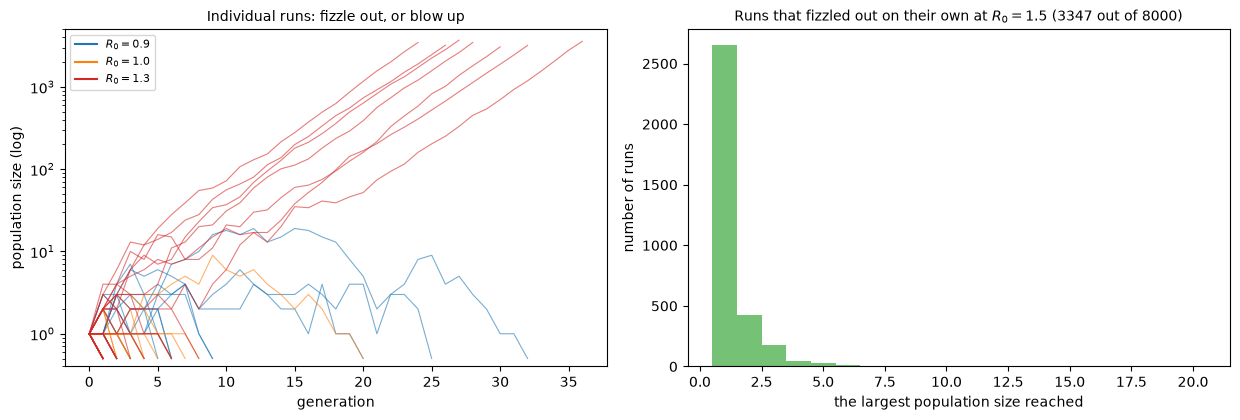

Of the runs that fizzled out, 97% never
exceeded three infected. A fizzle shows itself early, or not at all.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
for R0, color in ((0.9, "tab:blue"), (1.0, "tab:orange"), (1.3, "tab:red")):
    for _ in range(25):
        n, path = 1, [1]
        for _ in range(40):
            n = poisson(n * R0)
            path.append(n)
            if n == 0 or n > 3000:
                break
        ax.semilogy([max(v, 0.5) for v in path], lw=0.8, alpha=0.6, color=color)
    ax.plot([], [], color=color, label=f"$R_0 = {R0}$")
ax.set_xlabel("generation")
ax.set_ylabel("population size (log)")
ax.set_ylim(0.4, 5000)
ax.set_title("Individual runs: fizzle out, or blow up", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
R0 = 1.5
sizes = []
for _ in range(8000):
    v, g, big = simulate_branching(R0, maxgen=200, threshold=3000)
    if v:
        sizes.append(big)
ax.hist(sizes, bins=range(1, 22), align="left", alpha=0.65, color="tab:green")
ax.set_xlabel("the largest population size reached")
ax.set_ylabel("number of runs")
ax.set_title(f"Runs that fizzled out on their own at $R_0 = {R0}$ ({len(sizes)} out of 8000)", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Of the runs that fizzled out, {sum(1 for v in sizes if v <= 3) / len(sizes):.0%} never")
print(f"exceeded three infected. A fizzle shows itself early, or not at all.")

## Summary

| Concept | What to remember |
|---------|------------------|
| A branching process | every individual independently breeds $X$ offspring with the same distribution |
| $R_0 = E X$ | the single number that decides the fate of the process |
| The probability of extinction | **the smallest non-negative root of $s = G(s)$** |
| The phase transition | $R_0 \le 1$ ⟹ extinction is certain; $R_0 > 1$ ⟹ a positive hope of survival |
| The graphical proof | $G$ is convex, $G(1)=1$ ⟹ a root below 1 exists exactly when $G'(1) > 1$ |
| The critical case | at $R_0 = 1$ extinction is certain, but the mean time to it is **infinite** |
| The sum trick | the sum of $n$ Poissons is Poisson($n\lambda$) — a whole generation in one draw |
| The practical conclusion | even at $R_0 > 1$ most introductions fizzle out; that does not mean safety |

The feedback is what is new here: until now the events were independent, here every one breeds more.
The consequence is a sharp kink — and that is typical of all systems with amplifying feedback, from
epidemics to a chain reaction.

### Try it yourself

1. Replace the Poisson distribution of the offspring with a geometric one of the same $R_0$.
   Extinction then has a **closed formula** — derive it from $G(s) = \frac{p}{1-(1-p)s}$ and compare
   it with the simulation.
2. How does $q$ change if instead of a single introduced individual you start with ten? (Hint: the
   branches are independent.)
3. Compute the distribution of the **total** number infected (not just the maximum) for $R_0 < 1$. The
   mean has the simple form $1/(1-R_0)$ — verify it.
4. Add vaccination: a fraction $v$ of the population is immune, so the effective $R_0' = R_0(1-v)$.
   What $v$ is needed for $R_0' < 1$ with $R_0 = 3$?
5. At $R_0 = 1$ measure how the maximum length of a run grows with the number of repetitions. Does it
   settle?
6. Limit the population (only $N$ people can be infected) and watch how the unbounded growth turns
   into an epidemic curve with a peak.